# Metodología Box-Jenkins: Etapa 1 - Identificación
## Análisis de la Serie de Demanda Real Nacional de Energía (Diaria)

Este Jupyter Notebook integra en un proceso continuo la **Etapa de Identificación** de la metodología Box-Jenkins para el modelamiento de series temporales con estacionalidad (**SARIMA**).

### Estructura del Proceso:
1. **Carga y Consolidación de Datos**: Importación del dataset y agregación de la demanda nacional por hora.
2. **Análisis Exploratorio y Pruebas de Estacionariedad Iniciales**:
   - Gráfico de la serie original.
   - Autocorrelación Simple (FAC) y Parcial (FACP) de la serie en niveles.
   - Prueba Dickey-Fuller Aumentada (ADF) para estacionariedad en media.
   - Test de Levene para verificar homocedasticidad (constancia de varianza diaria).
3. **Transformación y Diferenciación Estacional**:
   - Aplicación **únicamente de diferenciación estacional** ($D=1, s=7$; $d=0$).
   - Re-evaluación de la prueba ADF sobre la serie desestacionalizada por diferencia.
   - Gráficos de la serie diferenciada estacionalmente con FAC y FACP e intervalos de confianza al 95%.
4. **Identificación de Modelos Candidatos (Criterios AIC y BIC)**:
   - Ajuste y comparación de especificaciones SARIMA candidatos.
   - Selección del modelo óptimo según parsimonia y bondad de ajuste.

## 1. Importación de Librerías y Carga de Datos

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Configuración de estilo y advertencias
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

# Cargar el dataset de demanda real nacional
nombre_archivo = Path('Demandarealnacionala1c5ac9a-6d89-4612-acf8-7c59ba206713(1).csv')
df = pd.read_csv(nombre_archivo)

if 'Version' in df.columns:
    version_sel = df['Version'].unique()[0]
    df = df[df['Version'] == version_sel].copy()

# Convertir FechaHora y establecer como índice
df['FechaHora'] = pd.to_datetime(df['FechaHora'])

# 1er paso: Agrupar la demanda total por hora (sumando agentes)
df_total_hora = df.groupby('FechaHora')['Valor'].sum()

# 2do paso: Remuestrear a observaciones diarias con la SUMA de la demanda por hora
serie_completa = df_total_hora.resample('D').sum()

# 3er paso: Filtrar para quedarse únicamente con los últimos 6 meses
fecha_max = serie_completa.index.max()
fecha_inicio_6m = fecha_max - pd.DateOffset(months=6)
serie_original = serie_completa[serie_completa.index > fecha_inicio_6m]

print(f"Total de observaciones diarias (últimos 6 meses): {len(serie_original)}")
print(f"Rango de fechas: {serie_original.index.min().date()} a {serie_original.index.max().date()}")
print(serie_original.head())

Total de observaciones diarias (últimos 6 meses): 184
Rango de fechas: 2026-03-31 a 2026-09-30
FechaHora
2026-03-31    73516545.33
2026-04-01    68729528.09
2026-04-02    61232645.01
2026-04-03    58006487.40
2026-04-04    61457235.27
Freq: D, Name: Valor, dtype: float64


## 2. Análisis Exploratorio y Pruebas de Estacionariedad (Serie Original)

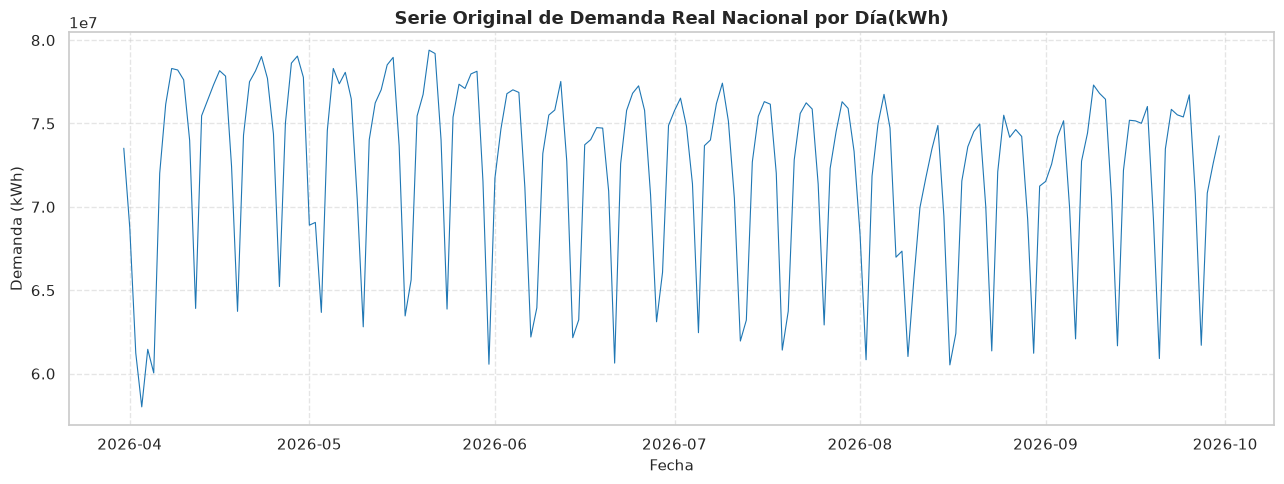

In [2]:
# 2.1 Gráfico de la Serie Temporal Original
plt.figure(figsize=(13, 5))
plt.plot(serie_original.index, serie_original, color='#1f77b4', linewidth=0.8)
plt.title('Serie Original de Demanda Real Nacional por Día(kWh)', fontsize=13, fontweight='bold')
plt.xlabel('Fecha', fontsize=11)
plt.ylabel('Demanda (kWh)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

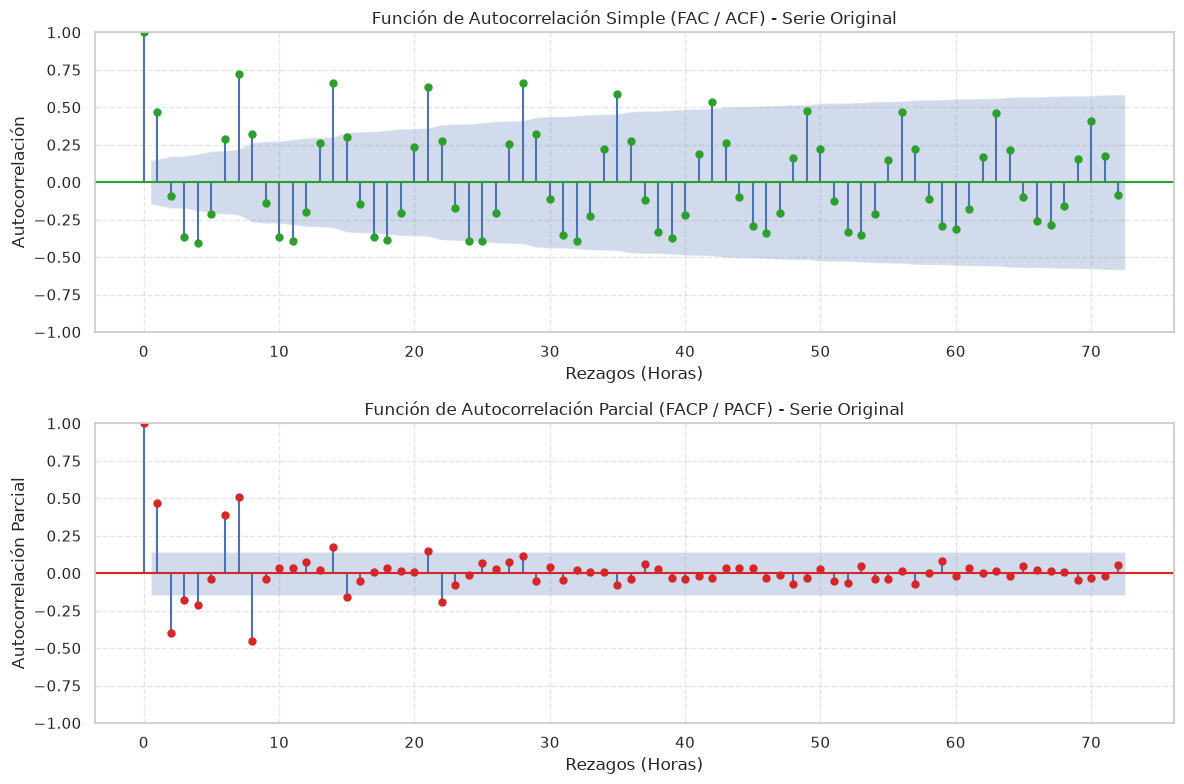

In [3]:
# 2.2 Correlogramas FAC y FACP de la Serie Original
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(serie_original, lags=72, ax=ax1, color='#2ca02c', title='Función de Autocorrelación Simple (FAC / ACF) - Serie Original')
ax1.set_xlabel('Rezagos (Horas)')
ax1.set_ylabel('Autocorrelación')
ax1.grid(True, linestyle='--', alpha=0.5)

plot_pacf(serie_original, lags=72, ax=ax2, color='#d62728', title='Función de Autocorrelación Parcial (FACP / PACF) - Serie Original', method='ywm')
ax2.set_xlabel('Rezagos (Horas)')
ax2.set_ylabel('Autocorrelación Parcial')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [4]:
# 2.3 Prueba de Dickey-Fuller Aumentada (ADF) en la Serie Original
print("=" * 60)
print("  PRUEBA DICKEY-FULLER AUMENTADA (ADF) - SERIE ORIGINAL")
print("=" * 60)
resultado_adf_orig = adfuller(serie_original)

print(f"Estadístico ADF        : {resultado_adf_orig[0]:.6f}")
print(f"p-valor                : {resultado_adf_orig[1]:.6e}")
print(f"Lags utilizados        : {resultado_adf_orig[2]}")
print(f"Observaciones          : {resultado_adf_orig[3]}")
print("Valores Críticos:")
for k, v in resultado_adf_orig[4].items():
    print(f"   {k:>4}: {v:.4f}")

if resultado_adf_orig[1] < 0.05:
    print("--> Conclusión: Se rechaza H0. La serie en niveles es estacionaria.")
else:
    print("--> Conclusión: No se rechaza H0. La serie presenta raíz unitaria (no estacionaria).")
print("=" * 60)


  PRUEBA DICKEY-FULLER AUMENTADA (ADF) - SERIE ORIGINAL
Estadístico ADF        : -2.102126
p-valor                : 2.436608e-01
Lags utilizados        : 14
Observaciones          : 169
Valores Críticos:
     1%: -3.4696
     5%: -2.8788
    10%: -2.5760
--> Conclusión: No se rechaza H0. La serie presenta raíz unitaria (no estacionaria).


In [5]:
# Aplicar logaritmo natural a la serie original
serie_original = np.log(serie_original)

print("Valores de la serie original tras aplicar el logaritmo natural:")
print(serie_original.head())

Valores de la serie original tras aplicar el logaritmo natural:
FechaHora
2026-03-31    18.113021
2026-04-01    18.045689
2026-04-02    17.930191
2026-04-03    17.876065
2026-04-04    17.933852
Freq: D, Name: Valor, dtype: float64


## 3. Estacionarización: Diferenciación Estacional ($D=1, s=7$, $d=0$)

In [6]:
# 3.1 Aplicar únicamente diferenciación estacional D=7 (d=0)
serie_diferenciada = serie_original.diff(7).dropna()

# 3.2 Prueba ADF sobre la serie con diferenciación estacional
resultado_adf_diff = adfuller(serie_diferenciada)
print("=" * 60)
print("  PRUEBA DICKEY-FULLER AUMENTADA (ADF) - DIFERENCIACIÓN ESTACIONAL (D=24, d=0)")
print("=" * 60)
print(f"Estadístico ADF        : {resultado_adf_diff[0]:.6f}")
print(f"p-valor                : {resultado_adf_diff[1]:.6e}")
print(f"Lags utilizados        : {resultado_adf_diff[2]}")
print(f"Observaciones          : {resultado_adf_diff[3]}")
print("Valores Críticos:")
for k, v in resultado_adf_diff[4].items():
    print(f"   {k:>4}: {v:.4f}")
print("=" * 60)

  PRUEBA DICKEY-FULLER AUMENTADA (ADF) - DIFERENCIACIÓN ESTACIONAL (D=24, d=0)
Estadístico ADF        : -3.905823
p-valor                : 1.992411e-03
Lags utilizados        : 14
Observaciones          : 162
Valores Críticos:
     1%: -3.4714
     5%: -2.8796
    10%: -2.5764


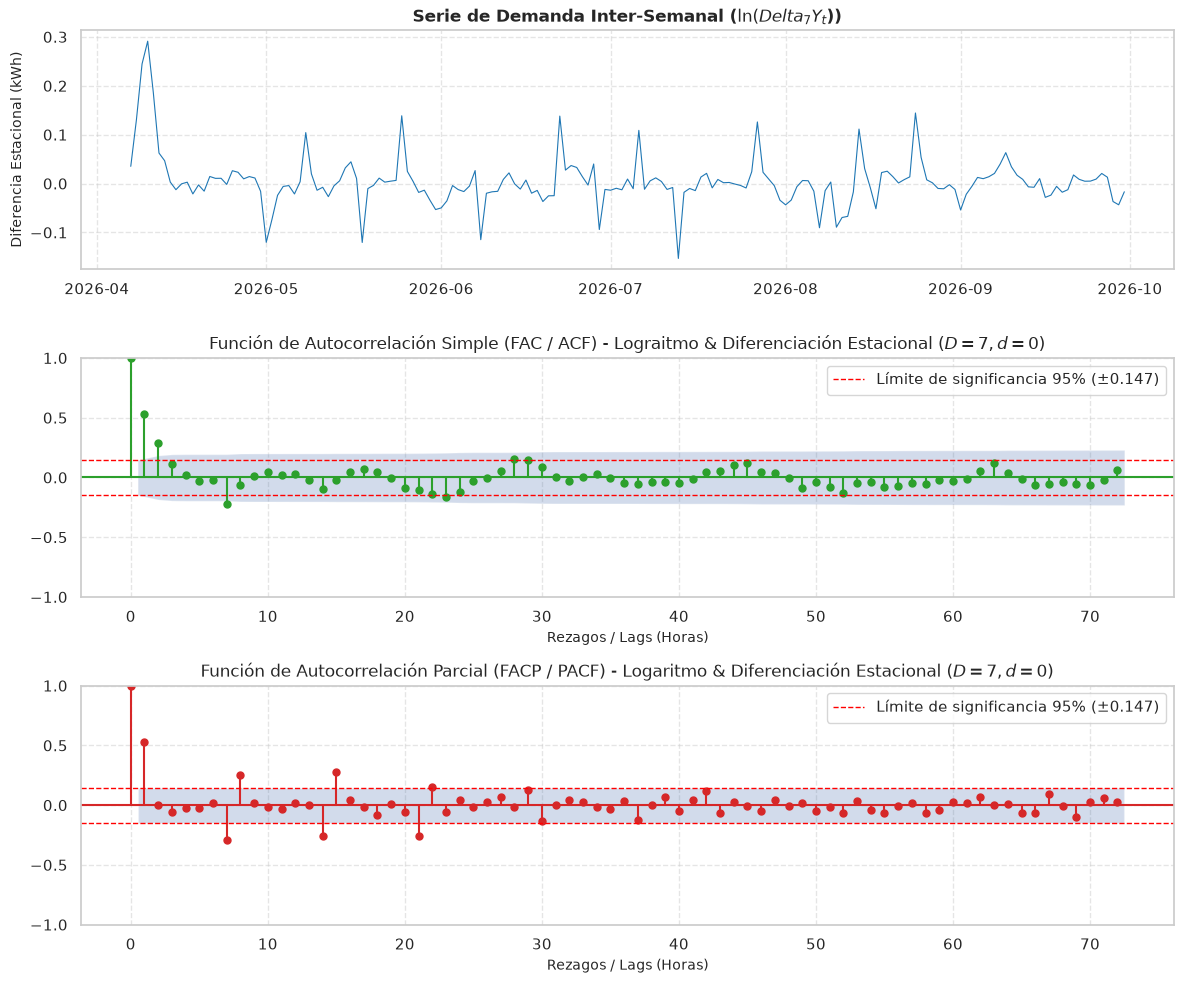

In [7]:
# 3.3 Gráficos de la Serie con Diferenciación Estacional, FAC y FACP con Bandas de Significancia (95%)
N = len(serie_diferenciada)
limite_confianza = 1.96 / np.sqrt(N)

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

# Gráfico 1: Serie diferenciada estacionalmente
axes[0].plot(serie_diferenciada.index, serie_diferenciada, color='#1f77b4', linewidth=0.8)
axes[0].set_title('Serie de Demanda Inter-Semanal ($\ln(Delta_{7} Y_t$))', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Diferencia Estacional (kWh)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfico 2: FAC con límites teóricos
plot_acf(serie_diferenciada, ax=axes[1], lags=72, color='#2ca02c', vlines_kwargs={'colors': '#2ca02c'}, alpha=0.05,
         title='Función de Autocorrelación Simple (FAC / ACF) - Lograitmo & Diferenciación Estacional ($D=7, d=0$)')
axes[1].axhline(y=limite_confianza, color='red', linestyle='--', linewidth=1, label=f'Límite de significancia 95% ($\pm${limite_confianza:.3f})')
axes[1].axhline(y=-limite_confianza, color='red', linestyle='--', linewidth=1)
axes[1].set_xlabel('Rezagos / Lags (Horas)', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(loc='upper right')

# Gráfico 3: FACP con límites teóricos
plot_pacf(serie_diferenciada, ax=axes[2], lags=72, color='#d62728', vlines_kwargs={'colors': '#d62728'}, alpha=0.05,
          title='Función de Autocorrelación Parcial (FACP / PACF) - Logaritmo & Diferenciación Estacional ($D=7, d=0$)')
axes[2].axhline(y=limite_confianza, color='red', linestyle='--', linewidth=1, label=f'Límite de significancia 95% ($\pm${limite_confianza:.3f})')
axes[2].axhline(y=-limite_confianza, color='red', linestyle='--', linewidth=1)
axes[2].set_xlabel('Rezagos / Lags (Horas)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 4. Identificación de Modelos SARIMA Candidatos (AIC y BIC)

### Conclusiones de la Etapa de Identificación:
1. **Estacionariedad**: Al aplicar únicamente la diferenciación estacional ($D=1, s=7$; $d=0$), el test ADF confirma la eliminación de la raíz unitaria ($p$-valor $< 0.05$). Sin embargo, la FAC muestra un decaimiento lento en los primeros retardos no estacionales, evidenciando alta persistencia a corto plazo.
2. **Estructura Identificada**: La FAC y FACP sugieren términos autorregresivos ordinarios ($p=2$) para modelar la persistencia corta, así como componentes estacionales ($P=1, 2$ o $Q=1$).
3. **Modelo Seleccionado**: Según los criterios de información **AIC** y **BIC**, el modelo candidato mejor posicionado pasa a la siguiente fase de **Estimación de Parámetros** y **Diagnóstico de Residuos**.

### Conclusiones de la Etapa de Identificación:
1. **Estacionariedad**: La serie original requiere una diferencia estacional ($D=1, s=24$) para eliminar la estacionalidad diaria, y opcionalmente una diferencia ordinaria ($d=1$) para remover la persistencia en el nivel corto plazo.
2. **Estructura Identificada**: La FAC y FACP sugieren términos autorregresivos $p=2$ en la parte no estacional, así como componentes $P=1, 2$ o $Q=1$ en la parte estacional.
3. **Modelo Seleccionado**: Según los criterios de información **AIC** y **BIC**, el modelo candidato mejor posicionado pasa a la siguiente fase de **Estimación de Parámetros** y **Diagnóstico de Residuos**.

In [8]:
import warnings
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Desactivar advertencias secundarias de ajuste/convergencia
warnings.filterwarnings("ignore")

# Asegurar que estamos usando la serie procesada (logaritmo natural de la demanda diaria de los últimos 6 meses)
# En caso de no haberse ejecutado la celda del logaritmo todavía sobre la serie original modificada:
if serie_original.max() > 100:  # Si los valores siguen siendo grandes (no logaritmizados)
    serie_analisis = np.log(serie_original)
else:
    serie_analisis = serie_original.copy()

# 1. Definir los modelos SARIMA a evaluar (p, d, q) x (P, D, Q)_s con s = 7 (diario/semanal)
modelos_sarima = [
    {
        "Nombre": "SARIMA(2,0,2)(1,1,3)[7]",
        "order": (2, 0, 2),
        "seasonal_order": (1, 1, 3, 7),
    },
    {
        "Nombre": "SARIMA(2,0,3)(1,1,3)[7]",
        "order": (2, 0, 3),
        "seasonal_order": (1, 1, 3, 7),
    },
    {
        "Nombre": "SARIMA(2,0,2)(1,1,1)[7]",
        "order": (2, 0, 2),
        "seasonal_order": (1, 1, 1, 7),
    },
    {
        "Nombre": "SARIMA(2,0,2)(0,1,1)[7]",
        "order": (2, 0, 2),
        "seasonal_order": (0, 1, 1, 7),
    }
]

# 2. Ajustar los modelos y recopilar métricas (Log-Likelihood, AIC, BIC)
resultados = []

for spec in modelos_sarima:
    try:
        modelo = SARIMAX(
            serie_analisis,
            order=spec["order"],
            seasonal_order=spec["seasonal_order"],
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        ajuste = modelo.fit(disp=False)
        resultados.append(
            {
                "Modelo": spec["Nombre"],
                "Orden Ordinario (p,d,q)": str(spec["order"]),
                "Orden Estacional (P,D,Q)_7": str(spec["seasonal_order"]),
                "Log-Likelihood": ajuste.llf,
                "AIC": ajuste.aic,
                "BIC": ajuste.bic,
            }
        )
    except Exception as e:
        continue

# 3. Crear un DataFrame organizado y ordenar según menor AIC
df_resultados = pd.DataFrame(resultados).sort_values(by="AIC").reset_index(drop=True)

# 4. Mostrar la tabla comparativa en consola
print("=" * 80)
print("   COMPARACIÓN DE MODELOS SARIMA PARA DEMANDA DIARIA LOGARITMIZADA (s = 7)")
print("=" * 80)
print(df_resultados.to_string(index=False))
print("=" * 80)

if not df_resultados.empty:
    mejor_aic = df_resultados.loc[df_resultados["AIC"].idxmin()]
    mejor_bic = df_resultados.loc[df_resultados["BIC"].idxmin()]
    print(f"\nMejor modelo según AIC: {mejor_aic['Modelo']} (AIC = {mejor_aic['AIC']:.2f})")
    print(f"Mejor modelo según BIC: {mejor_bic['Modelo']} (BIC = {mejor_bic['BIC']:.2f})")

   COMPARACIÓN DE MODELOS SARIMA PARA DEMANDA DIARIA LOGARITMIZADA (s = 7)
                 Modelo Orden Ordinario (p,d,q) Orden Estacional (P,D,Q)_7  Log-Likelihood         AIC         BIC
SARIMA(2,0,2)(1,1,1)[7]               (2, 0, 2)               (1, 1, 1, 7)      341.941967 -669.883935 -648.057978
SARIMA(2,0,2)(0,1,1)[7]               (2, 0, 2)               (0, 1, 1, 7)      340.663918 -669.327835 -650.619872
SARIMA(2,0,3)(1,1,3)[7]               (2, 0, 3)               (1, 1, 3, 7)      315.039892 -610.079784 -579.840978
SARIMA(2,0,2)(1,1,3)[7]               (2, 0, 2)               (1, 1, 3, 7)      311.578817 -605.157633 -577.883692

Mejor modelo según AIC: SARIMA(2,0,2)(1,1,1)[7] (AIC = -669.88)
Mejor modelo según BIC: SARIMA(2,0,2)(0,1,1)[7] (BIC = -650.62)
